### Online changepoint detection: latency against the divergence-based optimum

`CPA_divergences_CUSUM_mean.ipynb` measures how far apart the pre- and post-step ISI distributions are. This notebook turns that into a **latency**: how soon after the step can *any* online detector raise an alarm, for a given false-alarm rate?

With known pre/post distributions, the online CUSUM is the optimal detector (Lorden 1971, Moustakides 1986). For each ISI it adds the log-likelihood ratio $l = \log p_\mathrm{post} - \log p_\mathrm{pre}$ to $W_n = \max(0, W_{n-1} + l_n)$, and raises an alarm when $W_n > b$. For a threshold $b$ (Siegmund's approximations, iid ISIs):

| | | |
|---|---|---|
| mean delay | $\mathrm{ADD} \approx (b + e^{-b} - 1)\,/\,\mathrm{KL}(\mathrm{post}\|\mathrm{pre})$ | ISIs |
| mean time to a false alarm | $\mathrm{ARL}_0 \approx (e^{b} - b - 1)\,/\,\mathrm{KL}(\mathrm{pre}\|\mathrm{post})$ | ISIs |

So KL(post‖pre) sets the delay and KL(pre‖post) sets the false-alarm rate. Removing $b$ from these gives the optimal **operating characteristic** (OC): delay as a function of false-alarm rate (`optimal_delay`). For large $\mathrm{ARL}_0$ both approach Lai's (1998) asymptote, delay $\approx \ln \mathrm{ARL}_0 / \mathrm{KL}(\mathrm{post}\|\mathrm{pre})$. At realistic false-alarm rates that asymptote sits *above* the CUSUM, so it is not a hard bound.

**Converting to time.** False-alarm intervals are multiplied by the mean pre-step ISI. For delays, the first observation after the step is the ISI that straddles it. The step falls at a random point within an ISI, so that observation ends on average after the residual time $E[X^2]/2E[X]$. Each further observation adds a mean post-step ISI (`delay_to_ms`):

$$\text{delay [ms]} \approx \text{residual} + (\mathrm{ADD} - 1) \times \overline{\mathrm{ISI}}_\mathrm{post}$$

No detector can beat the residual, the time to the first post-step spike.

**Where the theory holds.** It is a continuous approximation, so it works when detection needs many ISIs (KL ≲ 1 nat/ISI, e.g. strong autapses or small steps). When KL ≫ 1, one or two ISIs are enough. Latency is then set by spike timing (residual plus part of an ISI), and the theory overestimates it, partly because the straddling ISI does carry some evidence (the step shortens it).

**What is measured.** For each condition, the repeats are split into a fit half and a test half. The pre/post distributions are fitted on the fit half (as in `cusum_analysis`), and on the test half:
* KL in both directions (held out, so they are not biased upwards by the fit)
* false-alarm rate: online CUSUM over the pre-step ISIs, restarting after each alarm
* delay: online CUSUM started at $W = 0$ at the step (Lorden's worst case), alarm time − step time

The theory uses only the two KLs and the firing rates. Where the empirical OC falls short of it, the cause is a model that does not hold: post-step transients, poor fits, ISI dependence that the model leaves out, or clipping. It also assumes the LLR is roughly Gaussian with variance 2 KL (small changes). When the LLR distribution is skewed or heavy-tailed, the true optimal OC differs even for iid ISIs, so the KL-only curve is an approximation to the optimum, not a strict bound.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import os
import warnings
import scipy.stats as stats
from joblib import Parallel, delayed
from tqdm import tqdm
import seaborn as sns
sns.set_theme()

from CP_functions import *

#### Check on synthetic data
Gamma ISIs (shape 4) whose scale drops from 25 to 20 ms at the step. The KL between gammas with the same shape has a closed form. For each threshold $b$, the simulated CUSUM OC should lie on `optimal_delay`. At a matched $b$, the Siegmund formulas underestimate both the delay and $\mathrm{ARL}_0$, because they ignore how far $W$ overshoots $b$. At a matched false-alarm rate the two errors cancel.

  b  ADD sim  ADD Siegmund  ARL0 sim  ARL0 Siegmund  ADD optimal at sim ARL0
0.5      3.8           1.2       6.7            1.4                      4.0
1.0      7.9           4.0      19.2            6.7                      8.0
1.5     12.5           7.8      42.9           18.4                     12.6
2.0     17.2          12.3      84.3           40.9                     17.4
2.5     22.6          17.1     155.9           80.8                     22.5
3.0     27.8          22.1     289.0          149.7                     28.1
3.5     33.5          27.3     505.1          266.4                     33.5
4.0     38.8          32.6     851.1          461.7                     38.7
4.5     44.2          37.9    1538.5          786.7                     44.8
5.0     50.1          43.3    2298.9         1325.7                     49.0
5.5     55.6          48.7    3389.8         2217.3                     53.1
6.0     61.3          54.0    5882.4         3690.3                     59.0

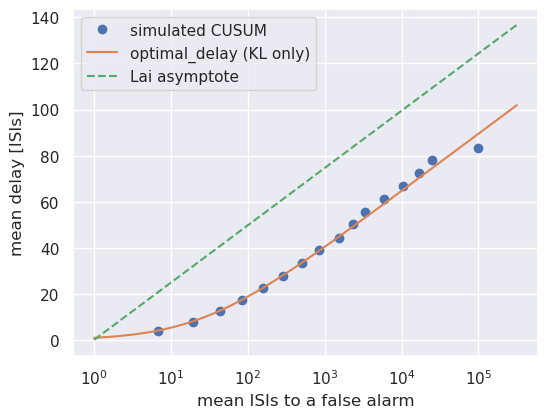

In [2]:
rng = np.random.default_rng(0)
k, th_pre, th_post = 4., 25., 20.
g_pre, g_post = stats.gamma(k, scale = th_pre), stats.gamma(k, scale = th_post)
kl_gamma = lambda tp, tq: k * (tp/tq - 1 - np.log(tp/tq))        # KL(gamma(k, tp) || gamma(k, tq))
kl_pp, kl_rev = kl_gamma(th_post, th_pre), kl_gamma(th_pre, th_post)

b_syn = np.linspace(0.5, 8, 16)
x = g_pre.rvs(200_000, random_state = rng)                          # long pre-change run: false alarms
_, n_fa = online_cusum(g_post.logpdf(x) - g_pre.logpdf(x), b_syn)
arl_emp = len(x) / n_fa
first = np.array([online_cusum(g_post.logpdf(y) - g_pre.logpdf(y), b_syn)[0]
                  for y in g_post.rvs((2000, 400), random_state = rng)])
add_emp = (first + 1).mean(0)                                       # delay in ISIs (all detected within 400)

add_th, arl_th = cusum_theory(kl_pp, kl_rev, b_syn)
arl_line = np.logspace(0, 5.5, 200)
fig, ax = plt.subplots(1, 1, figsize = (6, 4.5))
ax.plot(arl_emp, add_emp, 'o', label = 'simulated CUSUM')
ax.plot(arl_line, optimal_delay(arl_line, kl_pp, kl_rev), label = 'optimal_delay (KL only)')
ax.plot(arl_line, lai_bound(kl_pp, arl_line), '--', label = 'Lai asymptote')
ax.set_xscale('log')
ax.set_xlabel('mean ISIs to a false alarm')
ax.set_ylabel('mean delay [ISIs]')
ax.legend()
print(pd.DataFrame({'b': b_syn, 'ADD sim': add_emp, 'ADD Siegmund': add_th,
                    'ARL0 sim': arl_emp, 'ARL0 Siegmund': arl_th,
                    'ADD optimal at sim ARL0': optimal_delay(arl_emp, kl_pp, kl_rev)}).round(1).to_string(index = False))

#### Settings
`METHOD` picks the ISI model: `'llr'` (1D ISI distributions) or `'llr_pair'` (first-order Markov, consecutive ISI pairs). `CLIP` applies to the online CUSUM only. The `cusum_analysis` pipeline clips at ±10, but the KL theory is for unclipped evidence, so the default is `None`. Results are cached in `CPA_online_{tag}_{METHOD}.pickle`; set `RECOMPUTE = True` to rerun.

In [3]:
tag = 'N100'
METHOD = 'llr_pair'          # 'llr' | 'llr_pair'
CLIP = None                  # clip on l for the online CUSUM (None = unclipped, as in the theory)
SPLIT = 0.5                  # fraction of repeats used to fit the distributions; the rest are tested
T_DISCARD = 200              # ms, as in simulate_w_cusum
B_GRID = np.geomspace(0.02, 15, 30) # CUSUM thresholds [nats]; small b is needed when false alarms are rare
FA_TARGET = 10_000           # ms: compare latencies at one false alarm per 10 s
N_TRANSIENT = 30             # ISIs after the step kept for the transient check
DROP_ZERO_NOISE = True       # at var = 0 the ISIs are almost fixed and the fits degenerate
RECOMPUTE = False            # the cache stores theory columns: rerun after changing CP_functions
SAVE = False                 # save plots

with open(f'CPA_cusum_mean_{tag}_spikes.pickle', 'rb') as file:
    saved = pickle.load(file)
changepoint, N_repeats = saved['changepoint'], saved['N_repeats']
variances = np.array([v for v in saved['var'] if not (DROP_ZERO_NOISE and v == 0)])
f_vals, d_H = saved['f_values'], saved['d_H']
outfile = f'CPA_online_{tag}_{METHOD}.pickle'
print(f"variances {variances}, f {f_vals}, steps {d_H}, {N_repeats} repeats, step at {changepoint} ms")

variances [12.5 25.  37.5 50. ], f [  0 100 150 200 220 240 260 280 300 350 400], steps [ 0  1  2  3  4  5 10 12 15 18 20 25 30 40 50], 100 repeats, step at 5000 ms


#### Per-condition worker
For one condition (variance, step height, f) it returns a condition-level dict (divergences, rates, transient trace) and one row per threshold $b$:

| Column | Meaning |
|---|---|
| `n alarms`, `pre time [ms]` | false alarms on the pre-step test ISIs, and the time they cover |
| `ARL0 [ms]` | mean time between false alarms, pre time / n alarms (NaN with no alarms: it is then at least `pre time`) |
| `detected` | fraction of test trials with an alarm after the step, before the end of the trial |
| `delay [ms]` | median of alarm time − step time over test trials (undetected trials count as infinite; NaN if fewer than half are detected) |
| `ADD theory [ms]`, `ARL0 theory [ms]` | Siegmund at this $b$ |
| `delay optimal [ms]` | `optimal_delay` at the empirical `ARL0`: what the optimal detector would achieve at the same false-alarm rate |
| `delay Lai [ms]` | Lai's asymptote at the empirical `ARL0` |

In [4]:
def online_condition(spike_rows, changepoint, method, b_grid, clip, split, t_discard, n_transient):
    warnings.simplefilter('ignore', RuntimeWarning)     # empty means for undetected / short trials
    pairs = method == 'llr_pair'
    refs = reference_pairs if pairs else reference_isis
    fitter = fit_isi_pair_distribution if pairs else fit_isi_distribution

    isis = [spike_isis(s, t_discard) for s in spike_rows]
    n_fit = int(len(isis) * split)
    fit, test = isis[:n_fit], isis[n_fit:]
    fit_pre, fit_post = refs(fit, changepoint)
    test_pre, test_post = refs(test, changepoint)
    dist_pre, name_pre, _ = fitter(fit_pre)
    dist_post, name_post, _ = fitter(fit_post)
    if dist_pre is None or dist_post is None or len(test_pre) == 0 or len(test_post) == 0:
        return None, None

    # held-out divergences, unclipped and with the +-10 clip of llr_cp
    div = distribution_divergences(dist_pre, dist_post, test_pre, test_post, pairs = pairs)
    lp = (lambda d, r: d.logpdf_cond(r[:, 0], r[:, 1])) if pairs else (lambda d, r: d.logpdf(r))
    l_on_post = lp(dist_post, test_post) - lp(dist_pre, test_post)
    l_on_pre = lp(dist_post, test_pre) - lp(dist_pre, test_pre)
    isi_pre, isi_post = (test_pre[:, 1], test_post[:, 1]) if pairs else (test_pre, test_post)
    kl, kl_rev = div['KL post||pre'], div['KL pre||post']
    mean_pre, mean_post, resid = isi_pre.mean(), isi_post.mean(), residual_isi(isi_post)

    # online CUSUM on the test trials
    n_alarms, pre_time = np.zeros(len(b_grid), dtype = int), 0.
    delays, transient = [], []
    for isi, t_isi in test:
        if len(isi) < 3:
            continue
        t, l = llr_trace(isi, t_isi, dist_pre, dist_post, pairs = pairs, clip = clip)
        isi_scored = isi[1:] if pairs else isi
        pre = t < changepoint
        n_alarms += online_cusum(l[pre], b_grid)[1]
        pre_time += isi_scored[pre].sum()
        # from W = 0 at the step: the first scored ISI is the one straddling it
        l_post, t_post = l[~pre], t[~pre]
        first = online_cusum(l_post, b_grid)[0]
        delays.append(np.where(first >= 0, t_post[first] - changepoint, np.inf))
        tr = np.full(n_transient, np.nan)
        tr[:min(n_transient, len(l_post))] = l_post[:n_transient]
        transient.append(tr)
    delays = np.array(delays)

    arl0 = np.where(n_alarms > 0, pre_time / np.maximum(n_alarms, 1), np.nan)
    med = np.median(delays, axis = 0)
    add_th, arl_th = cusum_theory(kl, kl_rev, b_grid) if kl > 0 and kl_rev > 0 else (np.full(len(b_grid), np.nan),) * 2
    if kl > 0 and kl_rev > 0:
        opt = delay_to_ms(optimal_delay(arl0 / mean_pre, kl, kl_rev), mean_post, resid)
        lai = delay_to_ms(lai_bound(kl, arl0 / mean_pre), mean_post, resid)
    else:
        opt = lai = np.full(len(b_grid), np.nan)

    rows = pd.DataFrame({'b': b_grid, 'n alarms': n_alarms, 'pre time [ms]': pre_time, 'ARL0 [ms]': arl0,
                         'detected': np.isfinite(delays).mean(0),
                         'delay [ms]': np.where(np.isfinite(med), med, np.nan),
                         'mean delay detected [ms]': np.nanmean(np.where(np.isfinite(delays), delays, np.nan), 0)
                                                     if np.isfinite(delays).any() else np.nan,
                         'ADD theory [ms]': delay_to_ms(add_th, mean_post, resid), 'ARL0 theory [ms]': arl_th * mean_pre,
                         'delay optimal [ms]': opt, 'delay Lai [ms]': lai})
    info = {'pre dist': name_pre, 'post dist': name_post, 'KL post||pre': kl, 'KL pre||post': kl_rev,
            'JS divergence': div['JS divergence'],
            'KL post||pre clipped': np.mean(np.clip(l_on_post, -10, 10)),
            'KL pre||post clipped': -np.mean(np.clip(l_on_pre, -10, 10)),
            'mean ISI pre [ms]': mean_pre, 'mean ISI post [ms]': mean_post, 'residual [ms]': resid,
            'transient': np.nanmean(np.array(transient), 0)}
    return info, rows


conditions = [(v, h, f) for v in variances for h in d_H for f in f_vals]
if os.path.exists(outfile) and not RECOMPUTE:
    with open(outfile, 'rb') as file:
        cond, res = pickle.load(file)
else:
    out = Parallel(n_jobs = -1)(
        delayed(online_condition)([saved['spikes'][(rep, v, h, f)] for rep in range(N_repeats)], changepoint,
                                  METHOD, B_GRID, CLIP, SPLIT, T_DISCARD, N_TRANSIENT)
        for v, h, f in tqdm(conditions))
    cond_rows, res_rows = [], []
    for (v, h, f), (info, rows) in zip(conditions, out):
        if info is None:
            continue
        key = {'variance': v, 'step_height': h, 'autapse f': f}
        cond_rows.append({**key, **info})
        res_rows.append(rows.assign(**key))
    cond = pd.DataFrame(cond_rows)
    res = pd.concat(res_rows, ignore_index = True)
    with open(outfile, 'wb') as file:
        pickle.dump((cond, res), file)
print(f"{METHOD}: {len(cond)} conditions, {len(res)} (condition, b) rows")

llr_pair: 660 conditions, 19800 (condition, b) rows


#### Latency at a fixed false-alarm rate
Each condition's OC curve is interpolated (in log ARL₀) to one false alarm per `FA_TARGET`:
* `delay at FA (optimal)`: from the held-out KLs and firing rates alone
* `delay at FA (empirical)`: the online CUSUM on the test trials. Uses only thresholds with ≥ 3 false alarms; NaN when `FA_TARGET` is longer than the longest measured ARL₀. If even the lowest threshold has fewer false alarms than the target, its delay is used (achievable, so an upper bound)
* `delay at FA (Lai)`: the asymptote

In [5]:
def empirical_delay_at(sub, target):
    sub = sub.sort_values('b')
    # already fewer false alarms than the target at the lowest threshold: that delay is achievable
    lowest = sub.iloc[0]
    if lowest['pre time [ms]'] / max(lowest['n alarms'], 1) >= target:
        return lowest['delay [ms]']
    sub = sub[(sub['n alarms'] >= 3) & sub['delay [ms]'].notna()]
    if len(sub) < 2:
        return np.nan
    x = np.maximum.accumulate(np.log(sub['ARL0 [ms]'].values))    # ARL0 rises with b; drop count noise
    if not x[0] <= np.log(target) <= x[-1]:
        return np.nan
    return np.interp(np.log(target), x, sub['delay [ms]'].values)


cond_cols = ['variance', 'step_height', 'autapse f']
emp = res.groupby(cond_cols).apply(empirical_delay_at, FA_TARGET, include_groups = False).rename('delay at FA (empirical)')
cond = cond.drop(columns = [c for c in cond if c.startswith('delay at FA')]).merge(emp.reset_index(), on = cond_cols)
ok = (cond['KL post||pre'] > 0) & (cond['KL pre||post'] > 0)
kl, kl_rev = cond['KL post||pre'].clip(lower = 1e-12).values, cond['KL pre||post'].clip(lower = 1e-12).values
arl_isi = FA_TARGET / cond['mean ISI pre [ms]'].values
cond['delay at FA (optimal)'] = np.where(ok, delay_to_ms(optimal_delay(arl_isi, kl, kl_rev),
                                                         cond['mean ISI post [ms]'], cond['residual [ms]']), np.nan)
cond['delay at FA (Lai)'] = np.where(ok, delay_to_ms(lai_bound(kl, arl_isi), cond['mean ISI post [ms]'],
                                                     cond['residual [ms]']), np.nan)
cond['empirical / optimal'] = cond['delay at FA (empirical)'] / cond['delay at FA (optimal)']
step = cond[cond['step_height'] > 0]
print(step[['delay at FA (optimal)', 'delay at FA (empirical)', 'empirical / optimal']].describe().round(2))

       delay at FA (optimal)  delay at FA (empirical)  empirical / optimal
count                 614.00                   612.00               611.00
mean                  363.07                   372.98                 1.64
std                  1035.42                   549.12                 0.75
min                    14.12                    43.89                 0.15
25%                    43.54                    72.45                 1.02
50%                    81.77                   127.16                 1.57
75%                   346.96                   421.72                 2.20
max                 21336.37                  3363.39                 4.66


#### Operating characteristics for example conditions
Same examples as `CPA_divergences_CUSUM_mean.ipynb`: fixed input, autapse strength increasing to the right. Filled points are the online CUSUM on the test trials, one per threshold $b$. Open points had no false alarms, so their ARL₀ is only a lower bound. The solid line is the optimal OC predicted from the KLs, the dashed line Lai's asymptote, and the dotted line the residual (mean time to the first spike after the step).

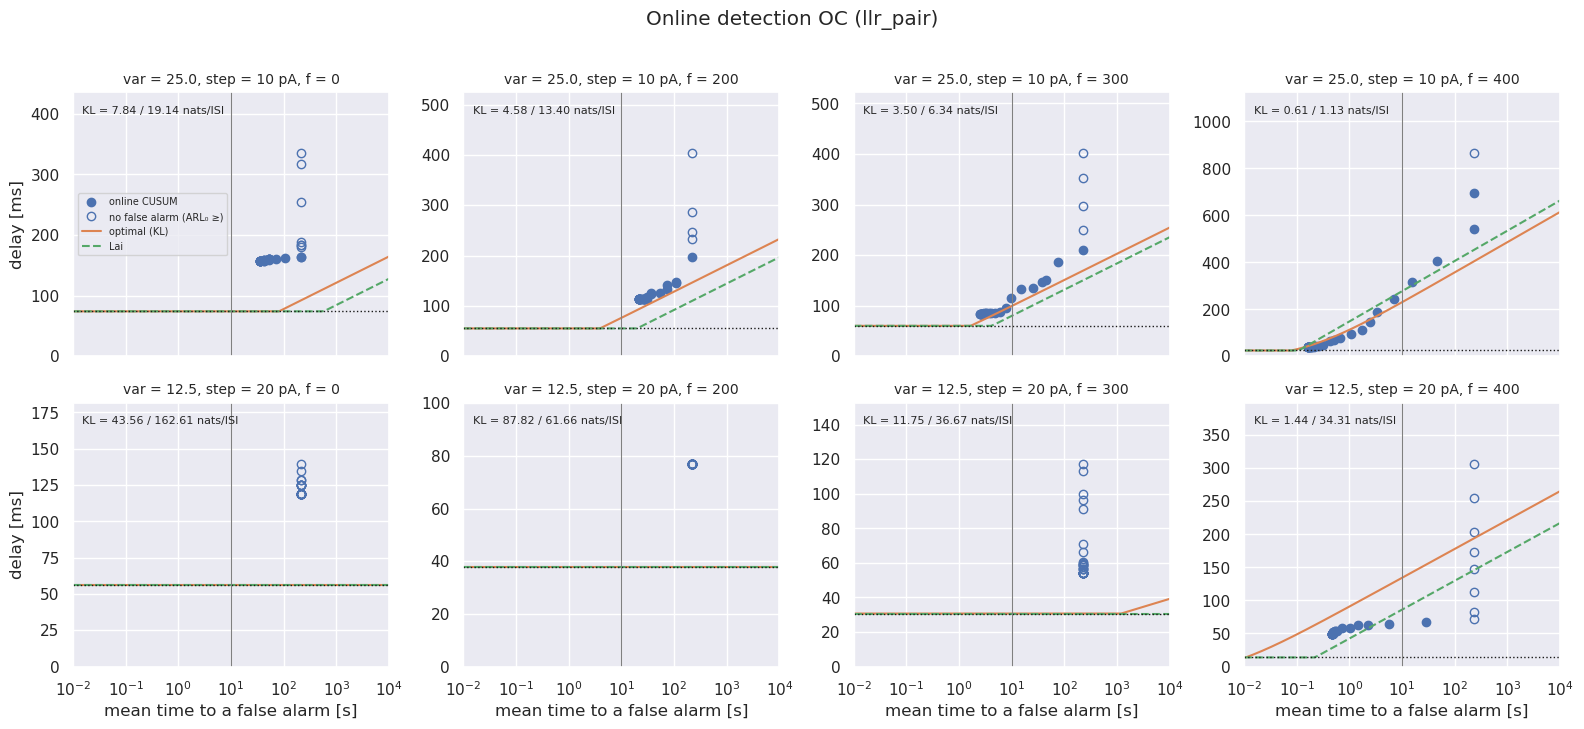

In [6]:
EXAMPLES = [(25.0, 10), (12.5, 20)]     # (variance, step height) rows
EXAMPLE_F = [0, 200, 300, 400]          # columns
b_fine = np.linspace(0.05, 30, 600)

fig, ax = plt.subplots(len(EXAMPLES), len(EXAMPLE_F), figsize = (4*len(EXAMPLE_F), 3.6*len(EXAMPLES)),
                       sharex = True, squeeze = False)
for r, (v, h) in enumerate(EXAMPLES):
    for c, f in enumerate(EXAMPLE_F):
        a = ax[r, c]
        sel = lambda df: df[(df['variance'] == v) & (df['step_height'] == h) & (df['autapse f'] == f)]
        if sel(cond).empty:
            a.set_visible(False)
            continue
        info, sub = sel(cond).iloc[0], sel(res)
        hit = sub['n alarms'] > 0
        a.plot(sub.loc[hit, 'ARL0 [ms]'] / 1000, sub.loc[hit, 'delay [ms]'], 'o', color = 'C0', label = 'online CUSUM')
        a.plot(sub.loc[~hit, 'pre time [ms]'] / 1000, sub.loc[~hit, 'delay [ms]'], 'o', mfc = 'none', color = 'C0',
               label = 'no false alarm (ARL₀ ≥)')
        add, arl = cusum_theory(info['KL post||pre'], info['KL pre||post'], b_fine)
        a.plot(arl * info['mean ISI pre [ms]'] / 1000, delay_to_ms(add, info['mean ISI post [ms]'], info['residual [ms]']),
               color = 'C1', label = 'optimal (KL)')
        arl_ms = np.logspace(1, 7, 100)
        a.plot(arl_ms / 1000, delay_to_ms(lai_bound(info['KL post||pre'], arl_ms / info['mean ISI pre [ms]']),
                                          info['mean ISI post [ms]'], info['residual [ms]']), '--', color = 'C2', label = 'Lai')
        a.axhline(info['residual [ms]'], color = 'k', ls = ':', lw = 1)
        a.axvline(FA_TARGET / 1000, color = 'grey', lw = 0.8)
        a.set_xscale('log')
        a.set_xlim(1e-2, 1e4)
        a.set_ylim(0, 1.3 * np.nanmax(np.r_[sub['delay [ms]'], info['residual [ms]']]))
        a.set_title(f'var = {v}, step = {h} pA, f = {f}', fontsize = 10)
        a.text(0.03, 0.95, f"KL = {info['KL post||pre']:.2f} / {info['KL pre||post']:.2f} nats/ISI",
               transform = a.transAxes, va = 'top', fontsize = 8)
for a in ax[-1]: a.set_xlabel('mean time to a false alarm [s]')
for a in ax[:, 0]: a.set_ylabel('delay [ms]')
ax[0, 0].legend(fontsize = 7, loc = 'center left')
fig.suptitle(f'Online detection OC ({METHOD})', y = 1.01)
fig.tight_layout()
if SAVE: plt.savefig(f'./plots/{tag}_{METHOD}_online_OC_examples.png', bbox_inches = 'tight')

#### Theory against simulation, all conditions
(a) Delay at the same false-alarm rate. Points on the diagonal reach the optimum predicted from the KLs; points above it fall short.
(b) ARL₀ at the same threshold. Siegmund ignores the overshoot, so the points sit above the diagonal even for iid data (synthetic check), which is why (a) matches on ARL₀ rather than on $b$.
Each point is one (condition, $b$) with ≥ 3 false alarms and step height > 0.

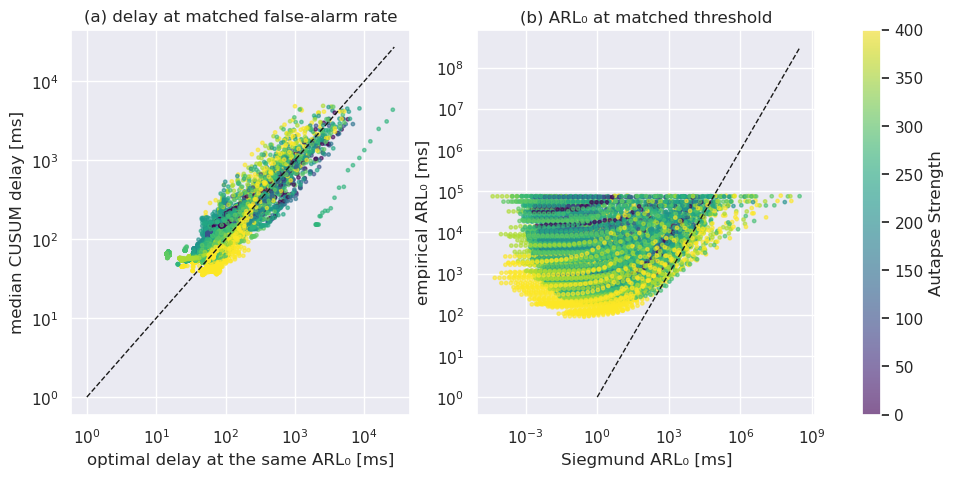

In [7]:
pts = res[(res['step_height'] > 0) & (res['n alarms'] >= 3)].dropna(subset = ['delay [ms]', 'delay optimal [ms]'])
fig, ax = plt.subplots(1, 2, figsize = (12, 5))
sc = ax[0].scatter(pts['delay optimal [ms]'], pts['delay [ms]'], c = pts['autapse f'], cmap = 'viridis', s = 6, alpha = 0.6)
ax[1].scatter(pts['ARL0 theory [ms]'], pts['ARL0 [ms]'], c = pts['autapse f'], cmap = 'viridis', s = 6, alpha = 0.6)
for a, (xl, yl) in zip(ax, [('optimal delay at the same ARL₀ [ms]', 'median CUSUM delay [ms]'),
                            ('Siegmund ARL₀ [ms]', 'empirical ARL₀ [ms]')]):
    lims = [max(min(a.get_xlim()[0], a.get_ylim()[0]), 1), max(a.get_xlim()[1], a.get_ylim()[1])]
    a.plot(lims, lims, 'k--', lw = 1)
    a.set_xscale('log'); a.set_yscale('log')
    a.set_xlabel(xl); a.set_ylabel(yl)
ax[0].set_title('(a) delay at matched false-alarm rate')
ax[1].set_title('(b) ARL₀ at matched threshold')
fig.colorbar(sc, ax = ax, label = 'Autapse Strength')
if SAVE: plt.savefig(f'./plots/{tag}_{METHOD}_online_theory_vs_empirical.png', bbox_inches = 'tight')

#### Latency at one false alarm per `FA_TARGET`
Against step height, one panel per noise level, lines are autapse strengths. Then against autapse strength, lines are step heights. Rows: the optimum from the KLs, the empirical online CUSUM, and their ratio (1 = optimal).

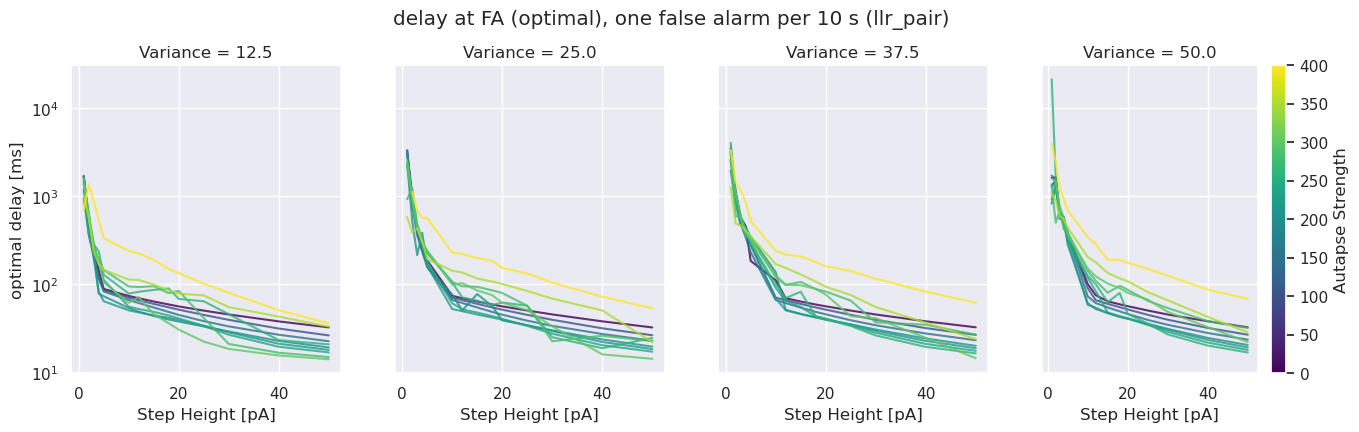

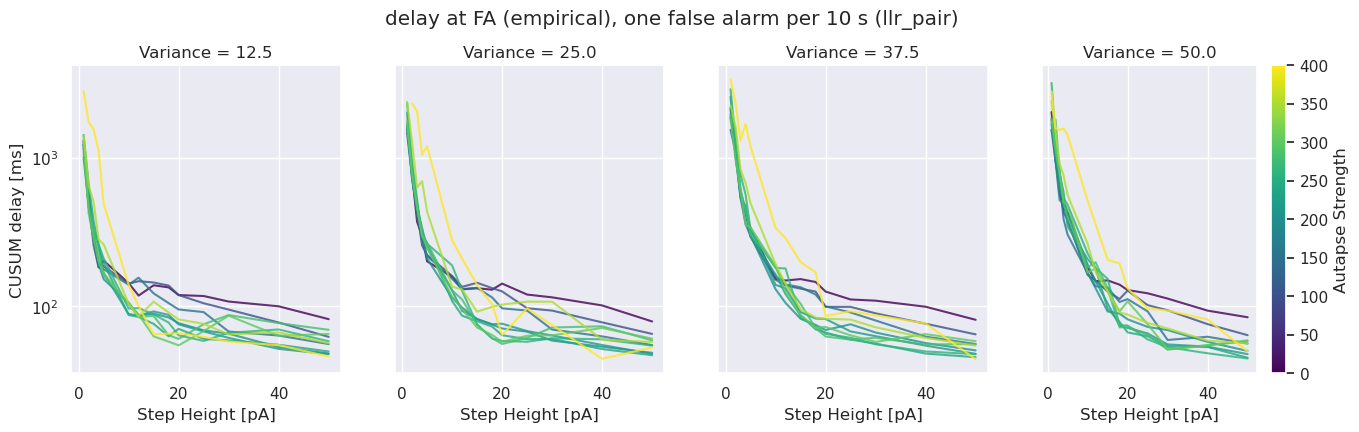

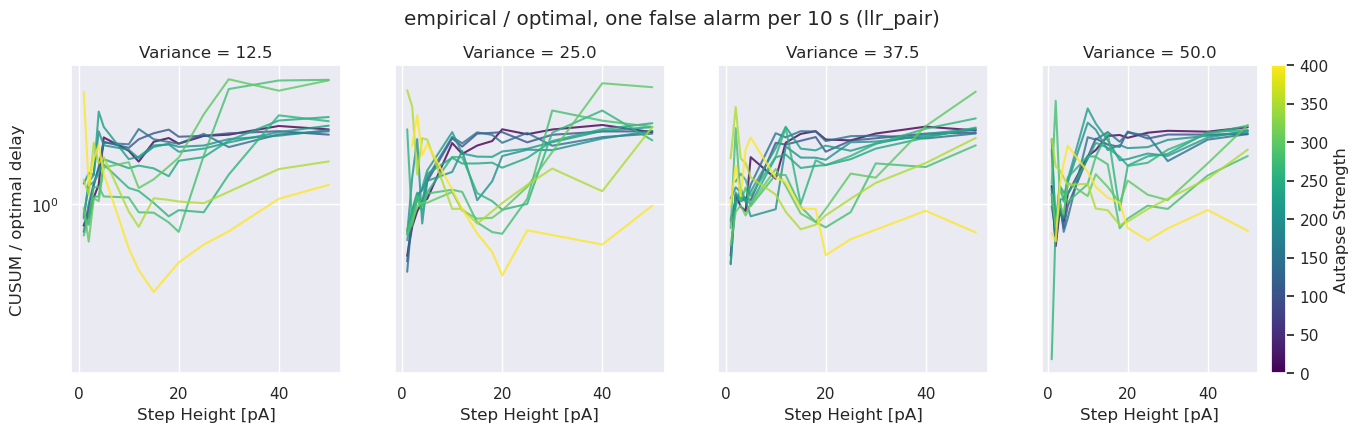

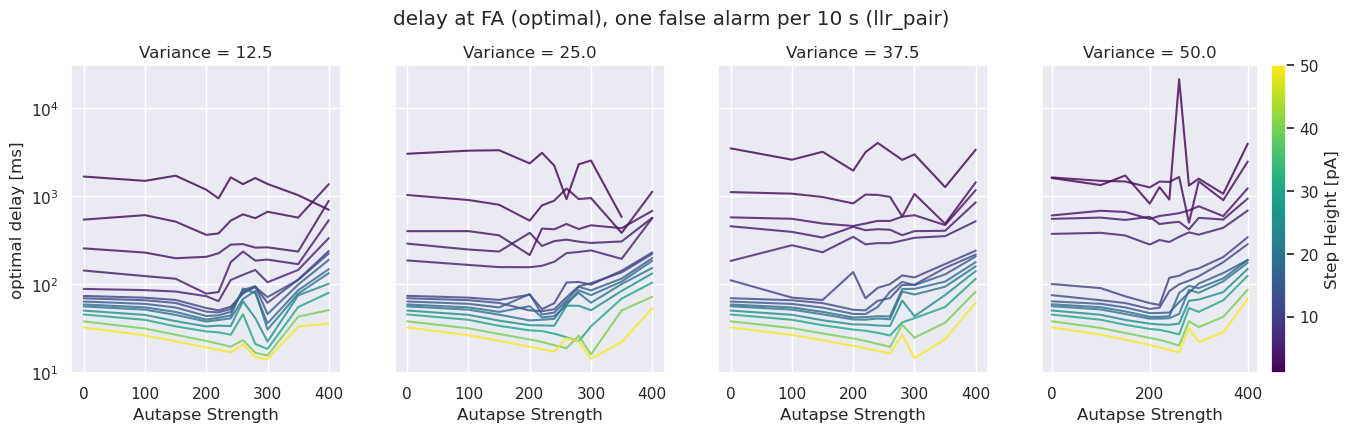

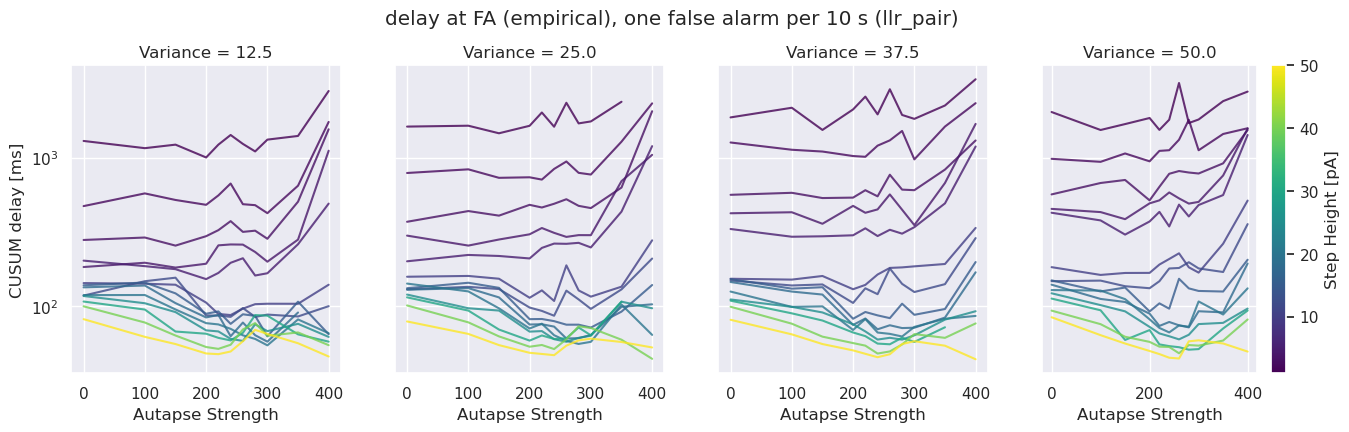

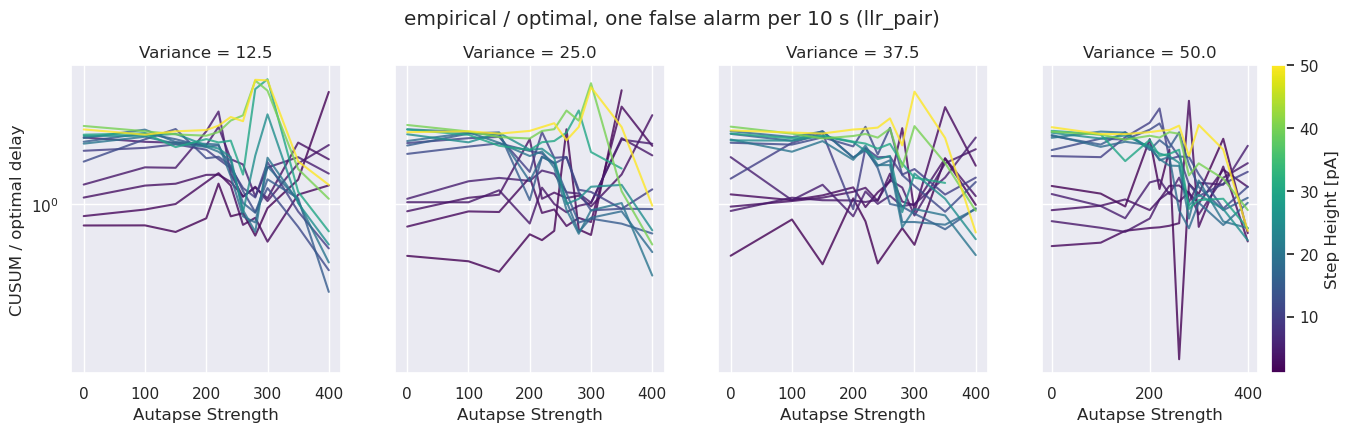

In [8]:
LATENCY = {
    'delay at FA (optimal)':   ('optimal delay [ms]', True),
    'delay at FA (empirical)': ('CUSUM delay [ms]', True),
    'empirical / optimal':     ('CUSUM / optimal delay', True),
}

def by_variance(df, y, label, x, hue, hue_label, log):
    fig, ax = plt.subplots(1, len(variances), figsize = (4*len(variances), 4), sharey = True, squeeze = False)
    ax = ax[0]
    for n, v in enumerate(variances):
        fig, ax[n] = psychometric_curve(df[df['variance'] == v], x = x, y = y, hue = hue, fig = fig, ax = ax[n],
                                        add_colorbar = n == len(variances) - 1, colorbar_label = hue_label)
        ax[n].set_title(f'Variance = {v}')
        if log:
            ax[n].set_yscale('log')
    ax[0].set_ylabel(label)
    fig.suptitle(f'{y}, one false alarm per {FA_TARGET/1000:g} s ({METHOD})', y = 1.02)
    return fig, ax

for y, (label, log) in LATENCY.items():
    fig, ax = by_variance(step, y, label, 'step_height', 'autapse f', 'Autapse Strength', log)
    for a in ax: a.set_xlabel('Step Height [pA]')
    if SAVE: plt.savefig(f'./plots/{tag}_{METHOD}_{y.replace(" ", "_").replace("/", "over")}_vs_step.png', bbox_inches = 'tight')
    plt.show()

for y, (label, log) in LATENCY.items():
    fig, ax = by_variance(step, y, label, 'autapse f', 'step_height', 'Step Height [pA]', log)
    for a in ax: a.set_xlabel('Autapse Strength')
    if SAVE: plt.savefig(f'./plots/{tag}_{METHOD}_{y.replace(" ", "_").replace("/", "over")}_vs_f.png', bbox_inches = 'tight')
    plt.show()

#### Cost of the ±10 clip
KL(post‖pre) from the clipped LLR against the unclipped one, on the held-out post-step ISIs. Points below the diagonal are conditions where the `cusum_analysis` clip removes evidence, so a clipped detector is slower than the theory.

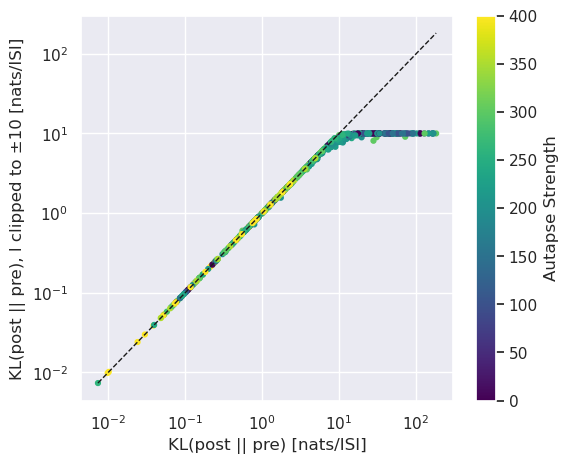

In [9]:
fig, ax = plt.subplots(1, 1, figsize = (6, 5))
sub = step[step['KL post||pre'] > 0]
sc = ax.scatter(sub['KL post||pre'], sub['KL post||pre clipped'], c = sub['autapse f'], cmap = 'viridis', s = 12)
lims = [sub['KL post||pre'].min(), sub['KL post||pre'].max()]
ax.plot(lims, lims, 'k--', lw = 1)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('KL(post || pre) [nats/ISI]')
ax.set_ylabel('KL(post || pre), l clipped to ±10 [nats/ISI]')
fig.colorbar(sc, ax = ax, label = 'Autapse Strength')
if SAVE: plt.savefig(f'./plots/{tag}_{METHOD}_online_clip_cost.png', bbox_inches = 'tight')

#### Post-step transients
Mean LLR of the n-th ISI after the step, averaged over test trials. The dashed line is the steady-state KL(post‖pre) the theory assumes. Index 0 is the ISI that straddles the step. If the early ISIs sit below the line, evidence arrives more slowly than the theory assumes, and the predicted latency is too optimistic.

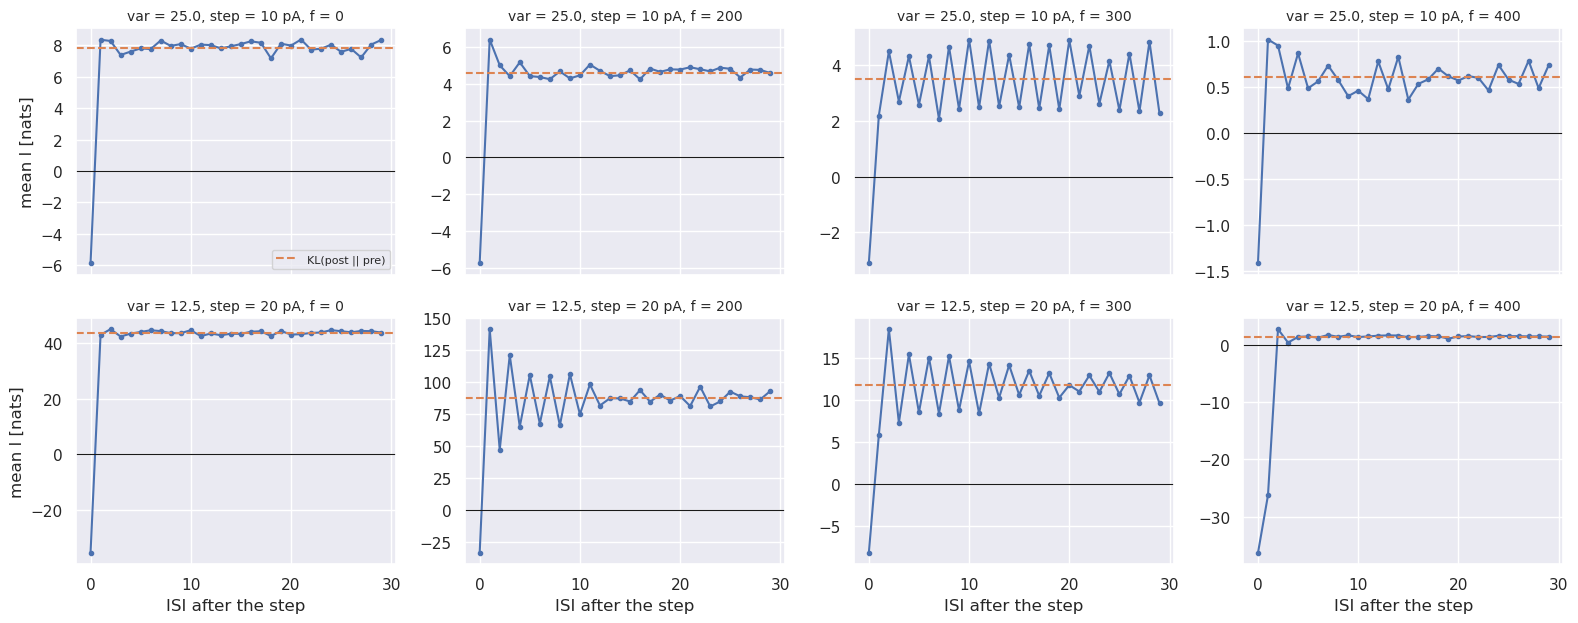

In [10]:
fig, ax = plt.subplots(len(EXAMPLES), len(EXAMPLE_F), figsize = (4*len(EXAMPLE_F), 3.2*len(EXAMPLES)),
                       sharex = True, squeeze = False)
for r, (v, h) in enumerate(EXAMPLES):
    for c, f in enumerate(EXAMPLE_F):
        row = cond[(cond['variance'] == v) & (cond['step_height'] == h) & (cond['autapse f'] == f)]
        if row.empty:
            ax[r, c].set_visible(False)
            continue
        row = row.iloc[0]
        ax[r, c].plot(row['transient'], 'o-', ms = 3)
        ax[r, c].axhline(row['KL post||pre'], color = 'C1', ls = '--', label = 'KL(post || pre)')
        ax[r, c].axhline(0, color = 'k', lw = 0.8)
        ax[r, c].set_title(f'var = {v}, step = {h} pA, f = {f}', fontsize = 10)
for a in ax[-1]: a.set_xlabel('ISI after the step')
for a in ax[:, 0]: a.set_ylabel('mean l [nats]')
ax[0, 0].legend(fontsize = 8)
fig.tight_layout()
if SAVE: plt.savefig(f'./plots/{tag}_{METHOD}_online_transients.png', bbox_inches = 'tight')

#### Findings
*To fill in after running both `METHOD`s.*
* Optimal latency at one false alarm per 10 s, against autapse strength:
* How close the online CUSUM gets to the optimum (`empirical / optimal`), and where it falls short:
* Transients / clipping: